# Implementations of Gradient Descent

為什麼需要梯度下降（GD）？
我們要最小化 LOSS 方式是每次調整參數，讓參數組合能找出最小 LOSS
怎麼做到？
透過GD 也就是對參數作導數 differenciate 他，得到移動的方向。deriviate 得到的正負號是方向，數值是移動大小，成上步伐就每次修正一點點。坡越陡，導數越大，走的步也越大；接近谷底時導數變小，步伐自然變小。
原因是：9.33 是「坡有多陡」，不是「離谷底多遠」。這兩個是不同的東西，單位也不同，不能直接拿來當距離走。


## Exercise 1: Gradient Descent

In this exercise, your task is to write a gradient descent algorithm, that finds the minimiser of $f$.

Let $f(x_1,x_2;a)=\frac{1}{2}(x_1^2+a\cdot x_2^2)$. Use the code we provide below as a base for your implementation. 

The starting point should be $(256,1)$.

In [1]:
import torch


In [2]:
# Part 1: Write the function f and its gradient df
import numpy as np

def f(x: np.ndarray, a: float) -> float:
    return 0.5 * (x[0]**2 + a * x[1]**2)

def df(x: np.ndarray, a: float) -> np.ndarray:
    return np.array([x[0], a*x[1]])


In [3]:
# Part 2: Implement gradient descent
def gradient_descent(a: float, step_size: float, num_steps: int) -> np.ndarray:
    """ Run Gradient descent
    Args:
        a: float, parameter in the function f
        step_size: float, the step size to use
        num_steps: int, number of steps to take
        
    Returns: out, list with the sequence of points considered during the descent.         
    """
    x = np.array([256.0, 1.0])
    out = [x.copy()]

    for _ in range(num_steps):
        x = x - step_size * df(x, a) # 這邊
        out.append(x.copy())

    return out

In [4]:
# Visualisation of the results
import matplotlib.pyplot as plt

def visualize(a: float, path: list, ax=None) -> None:
    """
    Make contour plot of f_a and plot the path on top of it
    """
    y_range = 10
    x = np.arange(-257, 257, 0.1)
    y = np.arange(-y_range, y_range, 0.1)
    xx, yy = np.meshgrid(x, y)
    z = 0.5 * (xx**2 + a * yy**2)
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8))
    h = ax.contourf(xx, yy, z, cmap=plt.get_cmap('PuBu_r'))
    ax.plot([x[0] for x in path], [x[1] for x in path], 'r.--', markersize=4)
    ax.plot([0], [0], 'rs', markersize=8) # optimal solution
    ax.set_xlim([-257, 257])
    ax.set_ylim([-y_range, y_range])
    pass

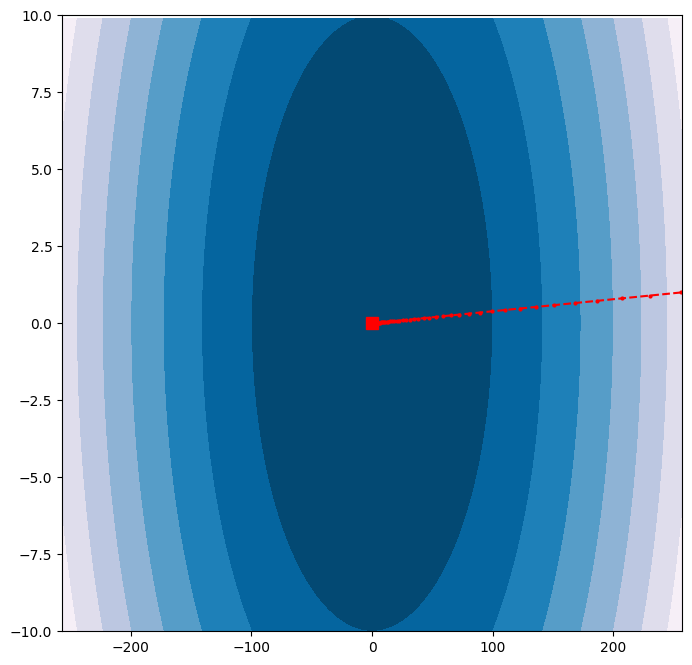

In [5]:
# Test your implementation
path = gradient_descent(a=1, step_size=0.1, num_steps=40)
visualize(a=100, path=path)

In [6]:
def gradient_descent_torch(a, step_size, num_steps, x0=(256.0, 1.0),
                           make_opt=lambda p, lr: torch.optim.SGD(p, 
                                                                  lr=lr,
                                                                  momentum=0.9,
                                                                  nesterov=True)):

    x = torch.tensor(x0, dtype=torch.float64, requires_grad=True)
    opt = make_opt([x], step_size)
    path = [x.detach().clone()]
    for _ in range(num_steps):
        opt.zero_grad()
        loss = 0.5 * (x[0]**2 + a * x[1]**2)   # 要和你 gradient_descent 裡的 f 一致
        loss.backward()
        opt.step()
        path.append(x.detach().clone())
    return torch.stack(path).numpy() 


# torch.optim.RMSprop(params, lr, alpha=0.9)
# torch.optim.Adam(params, lr)


[0. 0.]
[3.42207860e-07 1.33674945e-09]
[1.71369477 0.00669412]
[73.33776622  0.28647565]
[137.02518326   0.53525462]
[187.29330331   0.73161447]


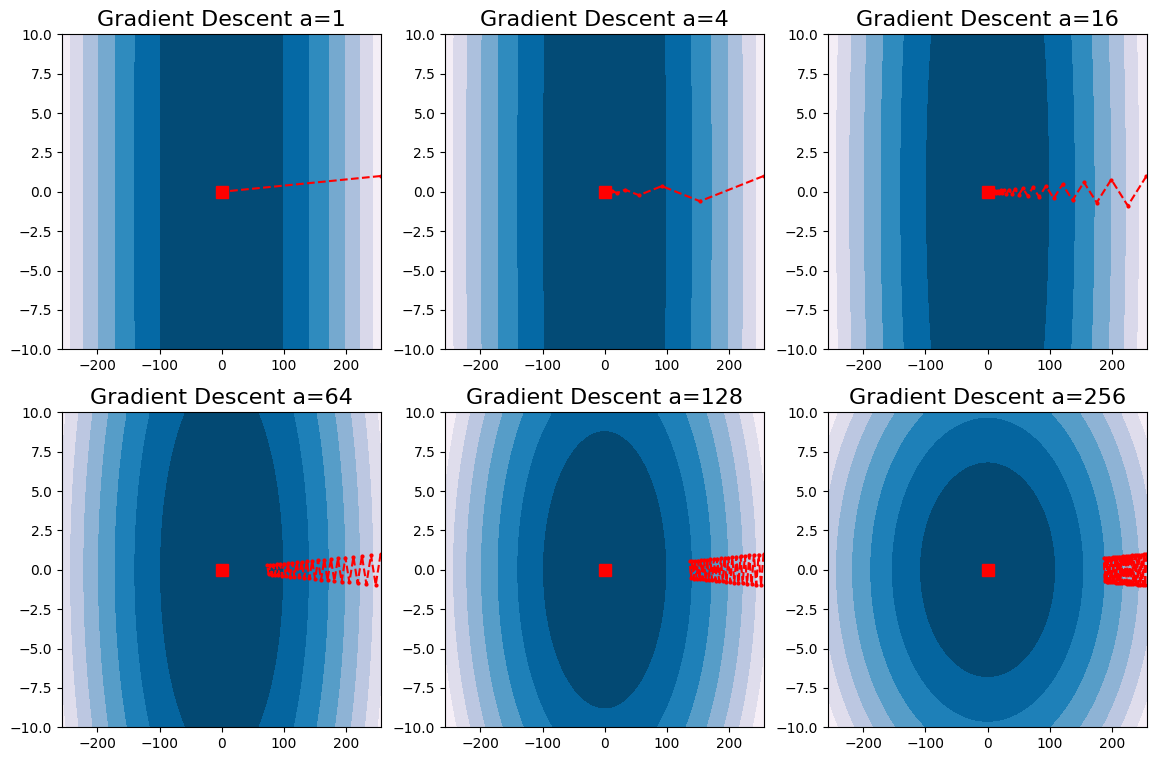

In [ ]:
# Part 3: Experiment with different values of a
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

a_values = [1, 4, 16, 64, 128, 256]
# with 1 step_size
# step_sizes = [1/a for a in a_values] ## inverse proportion / inverse ratio
step_sizes = [2/(a+1) for a in a_values]


# 1. the turning point appear at a=64, the 1-0.1*a give a value of new_x1 will be old_x1*-5.4
# 2. the z-zagging happens at each time minus val times positive or negative val next round
# 

for ax, a, step_size in zip(axes.flatten(), a_values, step_sizes):
    path = gradient_descent(a=a, step_size=step_size, num_steps=40)
    print(path[-1])
    visualize(a=a, path=path, ax=ax)
    ax.set_title('Gradient Descent a={0}'.format(a), fontsize=16)

---
## inverse ratio

a_values = [1, 4, 16, 64, 128, 256]

step_sizes = [1/a for a in a_values]

[0. 0.]
[0.00257449 0.        ]
[19.3682785  0.       ]
[136.35246202   0.        ]
[187.06391428   0.        ]
[218.90141565   0.        ]

這邊可以看到幾乎 x0 沒有修正 還是原先的 a 數值

---

## Exercise 2: Gradient Descent with Momentum
Extend your implementation of gradient descent to include momentum. You can use the following update rule:
$$v_{t+1} = \beta v_t + (1 - \beta) \nabla f(x_t)$$
$$x_{t+1} = x_t - \eta v_{t+1}$$
where $v_t$ is the velocity at time step $t$, $\beta$ is the momentum coefficient (typically between 0.9 and 0.99), $\eta$ is the learning rate, and $\nabla f(x_t)$ is the gradient of the function at point $x_t$.

To see the effect of using momentum propperly, we will need a more complicated cost landscape. Therefore we will use the Beale function, defined as:
$$f(x_1, x_2) = (1.5 - x_1 + x_1 x_2)^2 + (2.25 - x_1 + x_1 x_2^2)^2 + (2.625 - x_1 + x_1 x_2^3)^2$$

In [8]:
# Function and derivative are given:
def f(x: np.ndarray) -> float:
    return (1.5 - x[0] + x[0] * x[1])**2 + (2.25 - x[0] + x[0] * x[1]**2)**2 + (2.625 - x[0] + x[0] * x[1]**3)**2

def df(x: np.ndarray) -> np.ndarray:
    d1 = 2 * (1.5 - x[0] + x[0] * x[1]) * (-1 + x[1]) + 2 * (2.25 - x[0] + x[0] * x[1]**2) * (-1 + x[1]**2) + 2 * (2.625 - x[0] + x[0] * x[1]**3) * (-1 + x[1]**3)
    d2 = 2 * (1.5 - x[0] + x[0] * x[1]) * (x[0]) + 2 * (2.25 - x[0] + x[0] * x[1]**2) * (2 * x[0] * x[1]) + 2 * (2.625 - x[0] + x[0] * x[1]**3) * (3 * x[0] * x[1]**2)
    return np.array([d1, d2])

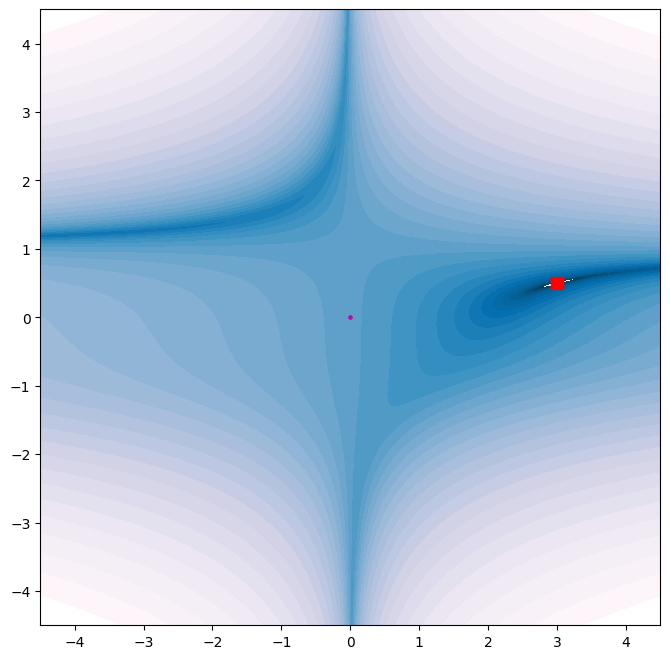

In [9]:
# Visualisation of the results
import matplotlib.pyplot as plt
from matplotlib import cm, ticker

def visualize_beale(base_path: list, momentum_path: list, ax=None) -> None:
    """ Make contour plot of f and plot the path on top of it
    """
    x = np.arange(-4.5, 4.5, 0.01)
    y = np.arange(-4.5, 4.5, 0.01)
    xx, yy = np.meshgrid(x, y)
    z = f(np.array([xx, yy]))
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8))
    h = ax.contourf(xx, yy, z, locator=ticker.LogLocator(), cmap=plt.get_cmap('PuBu_r'), levels=np.logspace(-2, 5, 35))
    ax.plot([x[0] for x in base_path], [x[1] for x in base_path], 'r.--', markersize=4)
    ax.plot([x[0] for x in momentum_path], [x[1] for x in momentum_path], 'm.--', markersize=4)
    ax.plot(3, 0.5, 'rs', markersize=8) # optimal solution
    ax.set_xlim([-4.5, 4.5])
    ax.set_ylim([-4.5, 4.5])
    pass

visualize_beale(base_path=[np.array([0, 0])], momentum_path=[np.array([0, 0])])

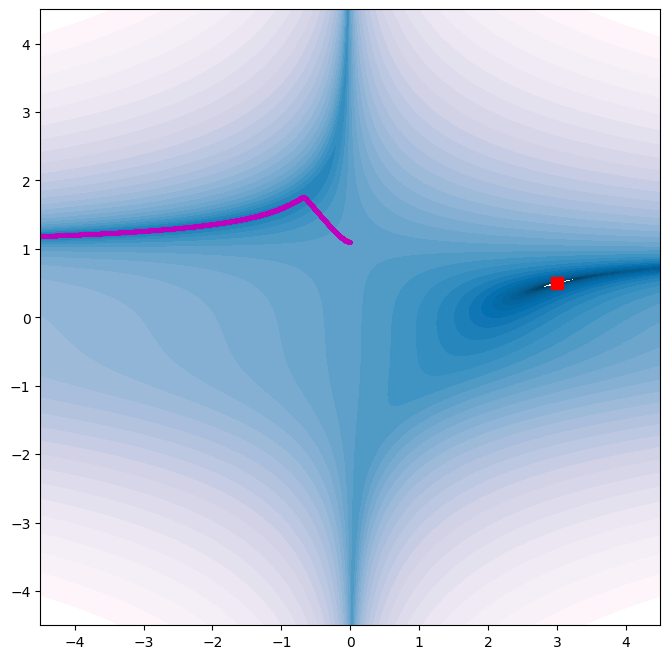

In [10]:
# Part 2: Implement gradient descent

def gradient_descent(x0: np.ndarray, step_size: float, num_steps: int) -> np.ndarray:
    """ Run Gradient descent
    Args:
        x0: np.ndarray, starting point
        step_size: float, the step size to use
        num_steps: int, number of steps to take
        
    Returns: out, list with the sequence of points considered during the descent.         
    """
    x = x0.copy()
    out = [x.copy()]

    for _ in range(num_steps):
        x = x - step_size * df(x)
        out.append(x.copy())
    
    return out

def gradient_descent_momentum(x0: np.ndarray, step_size: float, num_steps: int, b: float) -> np.ndarray:
    """ Run Gradient descent with momentum
    Args:
        x0: np.ndarray, starting point
        step_size: float, the step size to use
        num_steps: int, number of steps to take
        b: float, momentum parameter (0 <= b < 1)
        
    Returns: out, list with the sequence of points considered during the descent.         
    """
    x = x0.copy()
    v = np.array([0.0, 0.0])
    out = [x.copy()]

    for _ in range(num_steps):

        v = b * v + (1-b) * df(x)
        x = x - step_size * v
        out.append(x.copy())
    
    return out

# Test your implementation
start_point = np.array([0., 1.1]) ## (0,1) 這就是剛好讓整個是子得到 0 的點位，就像是鉛筆垂直站立的員心點。 v 會永遠 0

base_path = gradient_descent(x0=start_point, step_size=0.0001, num_steps=1000000)
momentum_path = gradient_descent_momentum(x0=start_point, step_size=0.0001, num_steps=1000000, b=0.9)
visualize_beale(base_path=base_path, momentum_path=momentum_path)


# 這邊的右側才是真的低點

## Exercise 3: Gradient-Free Optimization
This exercise is about implementing a gradient-free optimization algorithm, called Particle Swarm Optimization (PSO). The PSO algorithm is inspired by the social behavior of birds and fish. It is a population-based optimization algorithm that uses a swarm of particles to explore the search space and find the optimal solution.

This exercise will use another complex function in 2D, called the Rastrigin function. This time around we do not need to know the gradient of the function, merely to be able to evaluate the function at different points in the search space. 

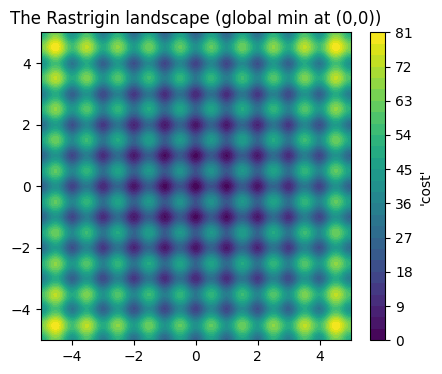

In [11]:
import matplotlib.pyplot as plt

def rastrigin(x, y):
    return 20 + x**2 + y**2 - 10 * (np.cos(2*np.pi*x) + np.cos(2*np.pi*y))

domain = (-5, 5)

xs = np.linspace(*domain, 200)
ys = np.linspace(*domain, 200)
X, Y = np.meshgrid(xs, ys)
Z = rastrigin(X, Y)

plt.figure(figsize=(5, 4))
plt.contourf(X, Y, Z, levels=30, cmap="viridis")
plt.title("The Rastrigin landscape (global min at (0,0))")
plt.colorbar(label="'cost'")
plt.show()

In [21]:
import numpy as np

n_particles = 600
n_iters = 60

# PSO hyperparameters
w  = 0.7   # inertia
c1 = 1.4   # cognitive (personal-best) pull
c2 = 1.4   # social (global-best) pull

# Generate arrays of positions and velocities, with each index corresponding to a particle in the swarm.
positions  = np.random.uniform(*domain, size=(n_particles, 2))
velocities = np.random.uniform(-1, 1, size=(n_particles, 2))

# Each particle 'remembers' its own personal best position found so far
pbest_pos = positions.copy()
pbest_val = rastrigin(positions[:, 0], positions[:, 1])

# Additionally, the swarm 'remembers' the global best position found so far
gbest_idx = np.argmin(pbest_val)
gbest_pos = pbest_pos[gbest_idx].copy()
gbest_val = pbest_val[gbest_idx]

In the part below, we have provided the loop that runs the PSO algorithm. Your task is to fill in the missing parts of the code (update equations for the velocity and position of each particle, as well as the update of the personal best and global best positions).

Hint: Each particle should move according to the following update equations:
$$v_i \leftarrow w \cdot v_i \;+\; c_1 r_1 (\text{pbest}_i - x_i) \;+\; c_2 r_2 (\text{gbest} - x_i)$$
$$x_i \leftarrow x_i + v_i$$
i.e., the new velocity of particle $i$ is a combination of its previous velocity, a pull towards its personal best position, and a pull towards the global best position. The new position of particle $i$ is then updated by adding the new velocity to its current position.

In [22]:
position_history = []   # positions of every particle, per iteration (for the animation)
gbest_history    = []   # the swarm's best-so-far, per iteration (for the animation)

for t in range(n_iters):
    position_history.append(positions.copy())
    gbest_history.append(gbest_pos.copy())

    for i in range(n_particles):
        r1, r2 = np.random.rand(), np.random.rand()

        ### Your code here (update velocity and position) ###
        velocities[i] = (w * velocities[i]
                         + c1 * r1 * (pbest_pos[i] - positions[i])
                         + c2 * r2 * (gbest_pos - positions[i]))
        positions[i]  = positions[i] + velocities[i]

        val = rastrigin(positions[i, 0], positions[i, 1])

        ### Your code here (update personal best) ###
        if val < pbest_val[i]:
            pbest_val[i] = val
            pbest_pos[i] = positions[i]

    ### Your code here (update global best) ###
    best_idx = np.argmin(pbest_val)
    if pbest_val[best_idx] < gbest_val:
        gbest_val = pbest_val[best_idx]
        gbest_pos = pbest_pos[best_idx].copy()

In [23]:
# For plotting and animating the PSO process
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(6, 6))

ax.contourf(X, Y, Z, levels=30, cmap="viridis")
scat = ax.scatter([], [], c="white", edgecolor="black", s=30)
star, = ax.plot([], [], marker="*", color="red", markersize=18, linestyle="none")
ax.set_xlim(domain)
ax.set_ylim(domain)
ax.set_title("PSO on the Rastrigin landscape")

def update(frame):
    pts = position_history[frame]
    scat.set_offsets(pts)
    g = gbest_history[frame]
    star.set_data([g[0]], [g[1]])
    ax.set_xlabel(f"iteration {frame}")
    return scat, star

anim = animation.FuncAnimation(fig, update, frames=len(position_history), interval=120, blit=True)
plt.close(fig)  # avoid a duplicate static plot showing up above the animation
HTML(anim.to_jshtml())